# Single Fidelity KAN Comparison

This workbook trains `SurrogateModels.mfkans.KANModel` (a single-fidelity Kolmogorov-Arnold Network) over 2D, 4D, 6D, 8D, and 10D analytical test functions, sweeping sample count to compare accuracy and cost -- mirroring `SingleFidelityComparison_NN.ipynb`'s approach for the NN case.

Single-model spot checks and width/grid exploration live in `SingleFidelityKANSpotChecks.ipynb` and `SingleFidelityKANWidthChecks.ipynb`. The `width`/`grid` settings below reflect what that exploration found:

- **2D**: `width=[2,5,5,1]`, `grid=[3,5]` -- validated healthy in the spot checks (clean train/test tracking, no divergence). No width bracket was run for 2D, so this is carried over as-is, not re-derived from a sweep like 4D/6D/8D were.
- **4D**: `width=[4,6,6,1]`, `grid=[3,5]` -- the original `[4,8,8,1]` baseline was oversized (overfits after refinement); `[4,6,6,1]` won a width bracket and held up across 3 seeds (mean error 0.134 vs baseline's 0.360).
- **6D**: `width=[6,12,12,1]`, `grid=[3,5]` -- baseline was already near-optimal (tied with `[6,9,9,1]`); both too-narrow and too-wide widths failed catastrophically (Goldilocks-zone pattern), unlike 4D.
- **8D**: `width=[8,16,16,1]`, `grid=[3,5]` -- baseline was the best of the widths tested, no catastrophic failures found across the bracket.
- **10D** (`WingWeight`, new): `width=[10,20,20,1]`, `grid=[3,5]` -- only a single feasibility run has been done (confirmed working, clean convergence), no width bracket yet. Sample range here is kept conservative (up to `n=1100`) since only `n=1000` has been validated.

All sweep cells here now also use `n_iter=400` (up from `300`) and `grid=[3,5]` (down from `[5,10]`, which caused clear overfitting in earlier spot checks), matching what was validated elsewhere.

Helper functions live in `examples/single_fidelity_kan_helpers.py` (analogous to `examples/single_fidelity_nn_helpers.py` for the NN case).

**Note on cost:** KAN training (LBFGS-based `fit`) is substantially slower per step than the NN's AdamW training loop, and cost grows with `width`, `grid`, and sample count. A full run of the original four sweep cells (grid=[5,10], n_iter=300) took roughly 20 hours; these updated settings use a cheaper grid schedule but more iterations and an added 10D section, so treat total runtime as being in the same multi-hour-to-dozens-of-hours regime rather than assuming it is shorter.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from examples import single_fidelity_kan_helpers as kan_helpers


## Important gotchas with `KANModel`

- `KANModel` does not cast its inputs -- the underlying `kan.KAN` network runs in `float32`, so `x_mat`/`y_vec` (and the test arrays) must already be `float32`, or training crashes with a dtype mismatch. `kan_helpers.create_test_points` and `kan_helpers.generate_kan_model(_comparisons)` handle this cast for you.
- `width` must start with the input dimension and end with the output dimension (`1` here), e.g. `[2, 5, 5, 1]` for the 2D case -- unlike `MLPNetwork`'s `hidden_layer_size`, which only specifies the hidden layers.
- `grid` is consumed (`grid.pop(0)`) as the model refines through each entry, so passing the same list object into multiple training runs would leave it empty after the first call. The helpers always hand `KANModel` a fresh copy, so you can safely reuse one `grid=[...]` default across calls.
- `KANModel` has no `scale_input`/`scale_output`/`bounds` options like `MLPNetwork` does -- inputs are used as given.

### 2-Dimensional Dataset

In [ ]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kan_helpers.create_test_points(my_function, n=1000)


checkpoint directory created: ./model
saving model version 0.0


| train_loss: 8.29e-06 | test_loss: 8.69e-01 | reg: 3.38e+01 | : 100%|█| 300/300 [01:11<00:00,  4.19


saving model version 0.1
saving model version 0.2


| train_loss: 1.36e-06 | test_loss: 8.66e-01 | reg: 3.38e+01 | : 100%|█| 300/300 [00:56<00:00,  5.33


saving model version 0.3
Run 2D :: seed 0 :: points 50 :: error 1.5687766075134277 :: train_time 128.20560380001552 
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 1.16e-04 | test_loss: 4.48e-01 | reg: 3.31e+01 | : 100%|█| 300/300 [02:54<00:00,  1.72


... (151 outputs left out)

| train_loss: 6.32e-03 | test_loss: 9.67e-03 | reg: 3.96e+01 | : 100%|█| 300/300 [05:08<00:00,  1.03


saving model version 0.1
saving model version 0.2


| train_loss: 1.17e-03 | test_loss: 3.10e-03 | reg: 3.78e+01 | : 100%|█| 300/300 [05:08<00:00,  1.03


saving model version 0.3
Run 2D :: seed 1 :: points 1000 :: error 0.005785774905234575 :: train_time 617.6019182999153 


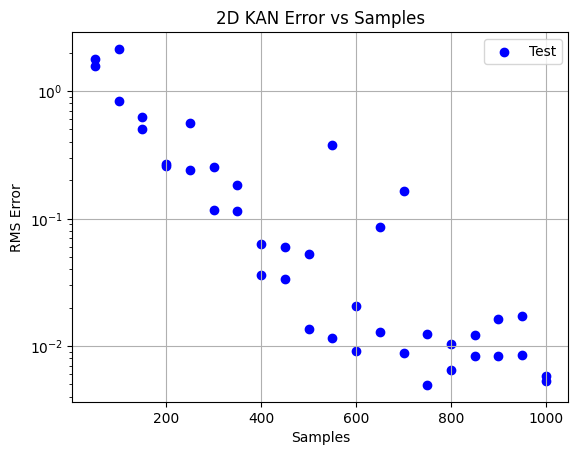

In [23]:
points_2d = []
model_error_2d = []
training_time_2d = []
evaluation_time_2d = []
points_2d, model_error_2d, evaluation_time_2d, training_time_2d = kan_helpers.generate_kan_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=50,
    sample_high=1001,
    step_size=50,
    seeds=2,
    points=points_2d,
    model_error=model_error_2d,
    training_time=training_time_2d,
    evaluation_time=evaluation_time_2d,
    width=[2, 5, 5, 1],
    grid=[3, 5],
    n_iter=400,
    output_file="kan_model_comparison_2d.csv",
)
ax = kan_helpers.plot_error_measure(points_2d, model_error_2d, "2D KAN Error vs Samples")
kan_helpers.save_plot(ax, "2D_sweep_grid3-5_width2-5-5-1")
plt.show()


### 4-Dimensional Dataset

In [ ]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kan_helpers.create_test_points(my_function, n=1000)


checkpoint directory created: ./model
saving model version 0.0


| train_loss: 4.05e-07 | test_loss: 8.55e-01 | reg: 4.32e+01 | : 100%|█| 300/300 [01:48<00:00,  2.76


saving model version 0.1
saving model version 0.2


| train_loss: 3.60e-07 | test_loss: 8.54e-01 | reg: 4.32e+01 | : 100%|█| 300/300 [01:12<00:00,  4.17


saving model version 0.3
Run 4D :: seed 0 :: points 50 :: error 86.08255004882812 :: train_time 181.50031389994547 
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 1.28e-06 | test_loss: 8.64e-01 | reg: 4.23e+01 | : 100%|█| 300/300 [01:59<00:00,  2.50


... (143 outputs left out)

| train_loss: 3.31e-04 | test_loss: 7.99e-04 | reg: 3.42e+01 | : 100%|█| 300/300 [04:58<00:00,  1.00


saving model version 0.1
saving model version 0.2


| train_loss: 1.47e-04 | test_loss: 4.38e-03 | reg: 3.36e+01 | : 100%|█| 300/300 [03:32<00:00,  1.41


saving model version 0.3
Run 4D :: seed 1 :: points 950 :: error 0.46052637696266174 :: train_time 512.1836220999248 


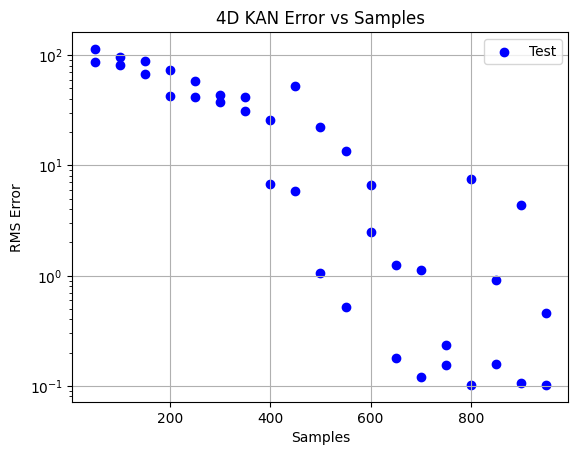

In [26]:
points_4d = []
model_error_4d = []
training_time_4d = []
evaluation_time_4d = []
points_4d, model_error_4d, evaluation_time_4d, training_time_4d = kan_helpers.generate_kan_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=50,
    sample_high=1000,
    step_size=50,
    seeds=2,
    points=points_4d,
    model_error=model_error_4d,
    training_time=training_time_4d,
    evaluation_time=evaluation_time_4d,
    width=[4, 6, 6, 1],
    grid=[3, 5],
    n_iter=400,
    output_file="kan_model_comparison_4d.csv",
)
ax = kan_helpers.plot_error_measure(points_4d, model_error_4d, "4D KAN Error vs Samples")
kan_helpers.save_plot(ax, "4D_sweep_grid3-5_width4-6-6-1")
plt.show()


### 6-Dimensional Dataset

In [ ]:
key = "6D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kan_helpers.create_test_points(my_function, n=1000)


checkpoint directory created: ./model
saving model version 0.0


| train_loss: 2.90e-07 | test_loss: 5.12e-01 | reg: 5.18e+01 | : 100%|█| 300/300 [01:29<00:00,  3.36


saving model version 0.1
saving model version 0.2


| train_loss: 1.69e-07 | test_loss: 5.04e-01 | reg: 5.18e+01 | : 100%|█| 300/300 [00:59<00:00,  5.05


saving model version 0.3
Run 6D :: seed 0 :: points 100 :: error 1.644532322883606 :: train_time 149.45141710015014 
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 5.14e-07 | test_loss: 2.64e-01 | reg: 4.91e+01 | : 100%|█| 300/300 [01:37<00:00,  3.09


... (143 outputs left out)

| train_loss: 1.61e-03 | test_loss: 1.44e-01 | reg: 4.57e+01 | : 100%|█| 300/300 [04:29<00:00,  1.11


saving model version 0.1
saving model version 0.2


| train_loss: 2.44e-04 | test_loss: 1.40e-01 | reg: 4.51e+01 | : 100%|█| 300/300 [04:17<00:00,  1.16


saving model version 0.3
Run 6D :: seed 1 :: points 1900 :: error 0.46147096157073975 :: train_time 528.3572132999543 


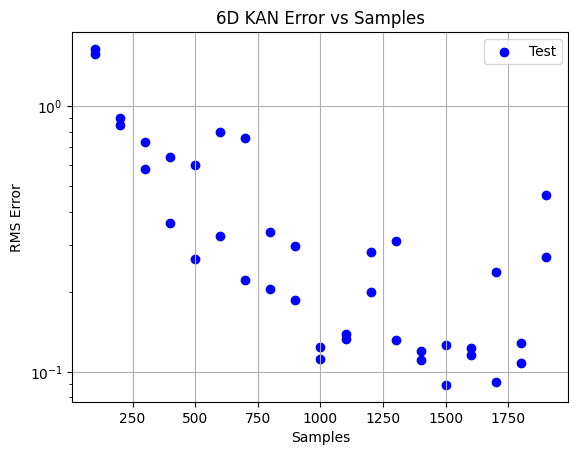

In [29]:
points_6d = []
model_error_6d = []
training_time_6d = []
evaluation_time_6d = []
points_6d, model_error_6d, evaluation_time_6d, training_time_6d = kan_helpers.generate_kan_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=100,
    sample_high=2000,
    step_size=100,
    seeds=2,
    points=points_6d,
    model_error=model_error_6d,
    training_time=training_time_6d,
    evaluation_time=evaluation_time_6d,
    width=[6, 12, 12, 1],
    grid=[3, 5],
    n_iter=400,
    output_file="kan_model_comparison_6d.csv",
)
ax = kan_helpers.plot_error_measure(points_6d, model_error_6d, "6D KAN Error vs Samples")
kan_helpers.save_plot(ax, "6D_sweep_grid3-5_width6-12-12-1")
plt.show()


### 8-Dimensional Dataset

In [ ]:
key = "8D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kan_helpers.create_test_points(my_function, n=1000)


checkpoint directory created: ./model
saving model version 0.0


| train_loss: 1.55e-07 | test_loss: 3.47e-01 | reg: 6.38e+01 | : 100%|█| 300/300 [01:16<00:00,  3.93


saving model version 0.1
saving model version 0.2


| train_loss: 1.39e-07 | test_loss: 3.48e-01 | reg: 6.38e+01 | : 100%|█| 300/300 [01:00<00:00,  4.95


saving model version 0.3
Run 8D :: seed 0 :: points 100 :: error 11.253995895385742 :: train_time 137.9714585999027 
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 7.18e-07 | test_loss: 1.74e-01 | reg: 5.60e+01 | : 100%|█| 300/300 [01:25<00:00,  3.52


... (151 outputs left out)

| train_loss: 6.54e-04 | test_loss: 1.15e-03 | reg: 4.54e+01 | : 100%|█| 300/300 [04:25<00:00,  1.13


saving model version 0.1
saving model version 0.2


| train_loss: 2.57e-04 | test_loss: 6.75e-04 | reg: 4.29e+01 | : 100%|█| 300/300 [04:28<00:00,  1.12


saving model version 0.3
Run 8D :: seed 1 :: points 3900 :: error 0.021795043721795082 :: train_time 535.0837570999283 


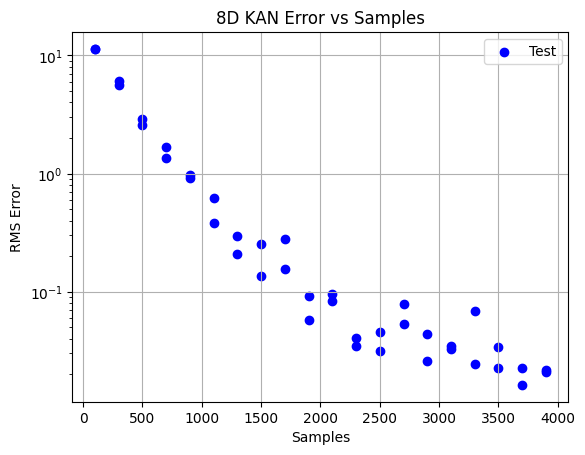

In [32]:
points_8d = []
model_error_8d = []
training_time_8d = []
evaluation_time_8d = []
points_8d, model_error_8d, evaluation_time_8d, training_time_8d = kan_helpers.generate_kan_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=100,
    sample_high=4000,
    step_size=200,
    seeds=2,
    points=points_8d,
    model_error=model_error_8d,
    training_time=training_time_8d,
    evaluation_time=evaluation_time_8d,
    width=[8, 16, 16, 1],
    grid=[3, 5],
    n_iter=400,
    output_file="kan_model_comparison_8d.csv",
)
ax = kan_helpers.plot_error_measure(points_8d, model_error_8d, "8D KAN Error vs Samples")
kan_helpers.save_plot(ax, "8D_sweep_grid3-5_width8-16-16-1")
plt.show()


### 10-Dimensional Dataset (WingWeight)

In [ ]:
key = "10D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kan_helpers.create_test_points(my_function, n=1000)


Run 10D :: seed 0 :: points 100 :: error 11.532950401306152 :: train_time 185.09181049998733 
Run 10D :: seed 0 :: points 200 :: error 5.090849876403809 :: train_time 183.78691729999264 
Run 10D :: seed 0 :: points 300 :: error 2.998363494873047 :: train_time 248.46349649998592 
Run 10D :: seed 0 :: points 400 :: error 0.3567321002483368 :: train_time 351.6185894999944 
Run 10D :: seed 0 :: points 500 :: error 0.41622135043144226 :: train_time 380.36414240000886 
Run 10D :: seed 0 :: points 600 :: error 0.8070557117462158 :: train_time 414.498929399997 
Run 10D :: seed 0 :: points 700 :: error 0.04242320731282234 :: train_time 454.06521490000887 
Run 10D :: seed 0 :: points 800 :: error 0.12175830453634262 :: train_time 489.1638222000038 
Run 10D :: seed 0 :: points 900 :: error 0.028914622962474823 :: train_time 386.0461478000216 
Run 10D :: seed 0 :: points 1000 :: error 0.022143155336380005 :: train_time 537.267748800019 
Run 10D :: seed 0 :: points 1100 :: error 0.01389874052256345

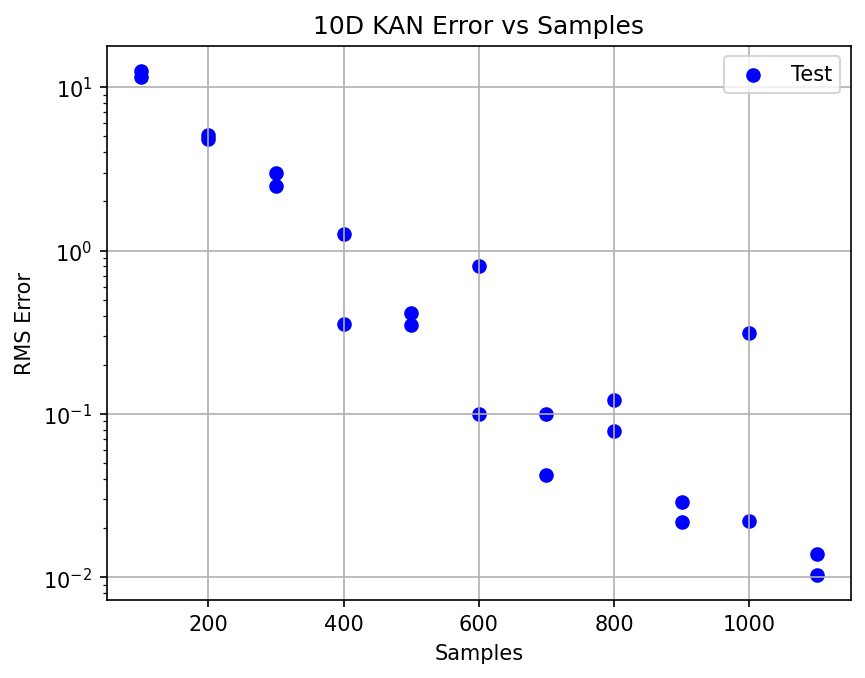

In [ ]:
points_10d = []
model_error_10d = []
training_time_10d = []
evaluation_time_10d = []
points_10d, model_error_10d, evaluation_time_10d, training_time_10d = kan_helpers.generate_kan_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=100,
    sample_high=1101,
    step_size=100,
    seeds=2,
    points=points_10d,
    model_error=model_error_10d,
    training_time=training_time_10d,
    evaluation_time=evaluation_time_10d,
    width=[10, 20, 20, 1],
    grid=[3, 5],
    n_iter=400,
    output_file="kan_model_comparison_10d.csv",
)
ax = kan_helpers.plot_error_measure(points_10d, model_error_10d, "10D KAN Error vs Samples")
kan_helpers.save_plot(ax, "10D_sweep_grid3-5_width10-20-20-1")
plt.show()
